# AIRS — анализ данных (EDA)

**AIRS** (Aerial Imagery for Roof Segmentation, Chen et al., ISPRS J. 2019): аэрофото Крайстчерча (Новая Зеландия),
7,5 см/пикс., маски крыш. Снимки и контуры зданий — LINZ, CC BY 4.0 («Crown Copyright Reserved»); у упаковки датасета
лицензия не указана. Вопрос анализа: **насколько AIRS похож на наш AOI** (Пушкин, снимок с дрона 7,3 см → 0,3 м) и
как его готовить, если подмешивать к обучению (ночной прогон `scripts/experiments/airs_night.py`).

Ноутбук только читает данные. Рисунки → `docs/datasets/figures/airs_*.png`, метрики → `reports/external_airs_eda.json`,
промежуточные таблицы → `data/interim/external/airs/eda/` (повторный запуск берёт их из кэша). Разметка `test`
нашего проекта не читается (сравнение — только с `train` и `val`).

In [ ]:
import json
import os
import random
from pathlib import Path

import cv2
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, display
from rasterio import features
from rasterio.enums import Resampling

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
candidates = [Path(os.environ["AIRS_DIR"])] if "AIRS_DIR" in os.environ else []
candidates += [REPO_ROOT / "data/raw/external/airs", Path.home() / "Downloads/archive-2"]
AIRS_DIR = next(p for p in candidates if (p / "train" / "image").is_dir())
FIG = REPO_ROOT / "docs/datasets/figures"
CACHE = REPO_ROOT / "data/interim/external/airs/eda"
REPORT = REPO_ROOT / "reports/external_airs_eda.json"
for d in (FIG, CACHE):
    d.mkdir(parents=True, exist_ok=True)

GSD = 0.075  # AIRS native, m/px
WORK = 0.3  # our working GSD (tiles 512 px), the night run downsamples x4
MIN_AREA = 12.0  # m2, same minimum as our annotation protocol
SPLITS = ("train", "val", "test")
N_SAMPLE = {"train": 60, "val": 15, "test": 15}  # tiles for per-building statistics
SEED = 42
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("AIRS_DIR =", AIRS_DIR)

AIRS_DIR = /Users/daniil.zhukov/Downloads/archive-2


## 1. Состав и метаданные

Пары «снимок — маска» по имени файла; `*_vis.tif` — визуальные копии масок, в анализ не идут.

In [ ]:
rows = []
for split in SPLITS:
    labels = {p.stem: p for p in (AIRS_DIR / split / "label").glob("*.tif")}
    for img in sorted((AIRS_DIR / split / "image").glob("*.tif")):
        lab = labels.get(img.stem)
        with rasterio.open(img) as s:
            b = s.bounds
            rows.append({"split": split, "tile": img.stem, "image": str(img),
                         "label": str(lab) if lab else None, "w": s.width, "h": s.height,
                         "bands": s.count, "dtype": s.dtypes[0], "crs": str(s.crs), "res": s.res[0],
                         "x0": b.left, "y0": b.bottom, "x1": b.right, "y1": b.top})
meta = pd.DataFrame(rows)
meta["area_km2"] = (meta.x1 - meta.x0) * (meta.y1 - meta.y0) / 1e6
summary = meta.groupby("split").agg(tiles=("tile", "size"), with_label=("label", "count"),
                                    area_km2=("area_km2", "sum"))
print(summary.round(1))
print("sizes:", meta[["w", "h"]].drop_duplicates().values.tolist(),
      "| bands/dtype:", meta[["bands", "dtype"]].drop_duplicates().values.tolist(),
      "| CRS:", meta.crs.unique().tolist(), "| res:", meta.res.unique().tolist())

       tiles  with_label  area_km2
split                             
test      95          95      53.4
train    857         857     474.7
val       94          94      52.1
sizes: [[10000, 10000], [10000, 3181], [2347, 10000]] | bands/dtype: [[3, 'uint8']] | CRS: ['EPSG:2193'] | res: [0.075, 0.07499999999999182, 0.07500000000000537, 0.07499999999999794]


## 2. Покрытие крышами по тайлам

Каждая маска читается с уменьшением ×16 (1,2 м) с усреднением — получаем долю пикселей крыш на тайле.
Доля «пустых» пикселей снимка (все каналы 0) — признак тайла на краю съёмки.

In [ ]:
cov_path = CACHE / "coverage.csv"
if cov_path.exists():
    cov = pd.read_csv(cov_path)
else:
    out = []
    for r in meta.itertuples():
        with rasterio.open(r.label) as s:
            lab = s.read(1, out_shape=(s.height // 16, s.width // 16),
                         resampling=Resampling.average, out_dtype="float32")
        with rasterio.open(r.image) as s:
            img = s.read(out_shape=(3, s.height // 16, s.width // 16), resampling=Resampling.nearest)
        out.append({"tile": r.tile, "split": r.split, "roof_share": float(lab.mean()),
                    "nodata_share": float((img.max(axis=0) == 0).mean())})
    cov = pd.DataFrame(out)
    cov.to_csv(cov_path, index=False)
cov = cov.merge(meta[["tile", "split", "x0", "y0", "x1", "y1"]], on=["tile", "split"])
print(cov.groupby("split")[["roof_share", "nodata_share"]].describe().round(3).T)
print("tiles without roofs:", int((cov.roof_share == 0).sum()),
      "| tiles with >10% nodata:", int((cov.nodata_share > 0.1).sum()))

split                 test    train     val
roof_share   count  95.000  857.000  94.000
             mean    0.072    0.077   0.070
             std     0.095    0.094   0.086
             min     0.000    0.000   0.000
             25%     0.001    0.002   0.000
             50%     0.018    0.021   0.024
             75%     0.159    0.146   0.137
             max     0.343    0.358   0.265
nodata_share count  95.000  857.000  94.000
             mean    0.025    0.047   0.060
             std     0.130    0.156   0.171
             min     0.000    0.000   0.000
             25%     0.000    0.000   0.000
             50%     0.000    0.000   0.000
             75%     0.000    0.000   0.000
             max     0.996    0.975   1.000
tiles without roofs: 166 | tiles with >10% nodata: 110


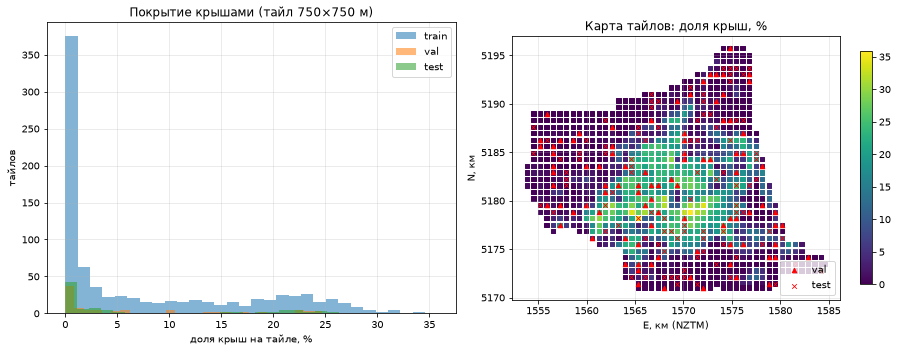

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for split in SPLITS:
    ax[0].hist(cov.loc[cov.split == split, "roof_share"] * 100, bins=30, alpha=0.55, label=split)
ax[0].set(xlabel="доля крыш на тайле, %", ylabel="тайлов", title="Покрытие крышами (тайл 750×750 м)")
ax[0].legend()
sc = ax[1].scatter((cov.x0 + cov.x1) / 2 / 1000, (cov.y0 + cov.y1) / 2 / 1000,
                   c=cov.roof_share * 100, s=18, cmap="viridis", marker="s")
for split, m in (("val", "^"), ("test", "x")):
    s = cov[cov.split == split]
    ax[1].scatter((s.x0 + s.x1) / 2 / 1000, (s.y0 + s.y1) / 2 / 1000, s=22, marker=m, c="red",
                  label=split, linewidths=0.8)
ax[1].set(xlabel="E, км (NZTM)", ylabel="N, км", title="Карта тайлов: доля крыш, %", aspect="equal")
ax[1].legend(loc="lower right")
fig.colorbar(sc, ax=ax[1], shrink=0.8)
plt.tight_layout()
plt.savefig(FIG / "airs_coverage.png")
plt.show()

## 3. Здания: размер, форма, плотность

На выборке тайлов маска уменьшается до нашего рабочего разрешения **0,3 м** (так её готовит ночной прогон),
здания — связные компоненты (8-связность), меньше 12 м² отбрасываются. Для сравнения — наша проверенная
разметка `train` и `val` (316 зданий).

* **прямоугольность** = площадь / площадь минимального описанного прямоугольника (1 — прямоугольник);
* **вытянутость** = длинная / короткая сторона этого прямоугольника;
* **слияние при уменьшении** — на части тайлов число компонент на 7,5 см и на 0,3 м: соседние крыши,
  разделённые щелью тоньше ~0,3 м, на рабочем разрешении сливаются в один «дом».

In [ ]:
def components(mask: np.ndarray, px_m: float) -> pd.DataFrame:
    n, cc, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    recs = []
    for k in range(1, n):
        area = stats[k, cv2.CC_STAT_AREA] * px_m**2
        if area < MIN_AREA:
            continue
        x, y, w, h = stats[k, :4]
        cnts, _ = cv2.findContours((cc[y:y + h, x:x + w] == k).astype(np.uint8),
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        (_, _), (a, b), _ = cv2.minAreaRect(max(cnts, key=cv2.contourArea))
        rect = max(a * b, 1.0) * px_m**2
        recs.append({"area_m2": area, "rectangularity": min(area / rect, 1.0),
                     "elongation": max(a, b) / max(min(a, b), 1.0)})
    return pd.DataFrame(recs)


rng = random.Random(SEED)
sample = pd.concat([meta[meta.split == s].sample(n=min(N_SAMPLE[s], (meta.split == s).sum()),
                                                  random_state=SEED) for s in SPLITS])
bld_path = CACHE / "buildings_sample.csv"
if bld_path.exists():
    bld = pd.read_csv(bld_path)
else:
    parts = []
    for r in sample.itertuples():
        with rasterio.open(r.label) as s:
            lab = s.read(1, out_shape=(s.height // 4, s.width // 4),
                         resampling=Resampling.average, out_dtype="float32")
        c = components(lab > 0.5, WORK)
        c["tile"], c["split"] = r.tile, r.split
        parts.append(c)
    bld = pd.concat(parts, ignore_index=True)
    bld.to_csv(bld_path, index=False)
# Edge tiles are cropped (e.g. 10000x3181 px): density uses each tile's own area. Our tiles were
# chosen where buildings are, so the fair comparison is with built-up AIRS tiles (roofs >= 5 %).
dens = (sample[["split", "tile", "area_km2"]]
        .merge(bld.groupby("tile").size().rename("n").reset_index(), on="tile", how="left")
        .merge(cov[["tile", "roof_share"]], on="tile").fillna({"n": 0}))
dens["per_km2"] = dens.n / dens.area_km2
built = dens[dens.roof_share >= 0.05]
print("buildings in sample:", len(bld), "on", bld.tile.nunique(), "tiles")
print("all sampled tiles:", dens.per_km2.describe().round(0).to_dict())
print("built-up tiles (roofs >= 5 %):", len(built), built.per_km2.describe().round(0).to_dict())

buildings in sample: 25113 on 79 tiles
all sampled tiles: {'count': 90.0, 'mean': 496.0, 'std': 640.0, 'min': 0.0, '25%': 23.0, '50%': 155.0, '75%': 821.0, 'max': 2103.0}
built-up tiles (roofs >= 5 %): 40 {'count': 40.0, 'mean': 1039.0, 'std': 618.0, 'min': 96.0, '25%': 486.0, '50%': 884.0, '75%': 1592.0, 'max': 2103.0}


In [ ]:
merge_path = CACHE / "downsample_merge.csv"
if merge_path.exists():
    merge = pd.read_csv(merge_path)
else:
    out = []
    for r in sample[sample.split == "train"].head(15).itertuples():
        with rasterio.open(r.label) as s:
            full = s.read(1) > 0
            low = s.read(1, out_shape=(s.height // 4, s.width // 4), resampling=Resampling.average,
                         out_dtype="float32") > 0.5
        out.append({"tile": r.tile, "n_native": len(components(full, GSD)),
                    "n_work": len(components(low, WORK))})
    merge = pd.DataFrame(out)
    merge.to_csv(merge_path, index=False)
merge_rate = 1 - merge.n_work.sum() / merge.n_native.sum()
print(merge.sum(numeric_only=True).to_dict(), f"-> lost by merging at 0.3 m: {merge_rate:.1%}")

{'n_native': 3847, 'n_work': 3808} -> lost by merging at 0.3 m: 1.0%


In [ ]:
ours = pd.concat([gpd.read_file(REPO_ROOT / f"data/labels/{s}/buildings.geojson").assign(split=s)
                  for s in ("train", "val")]).to_crs(32636)
ours = ours[ours.geometry.is_valid & (ours.geometry.area >= MIN_AREA)]
mrr = ours.geometry.minimum_rotated_rectangle()
sides = mrr.apply(lambda g: sorted(
    np.hypot(*np.diff(np.asarray(g.exterior.coords)[:3], axis=0).T)))
ours_df = pd.DataFrame({"area_m2": ours.geometry.area.values,
                        "rectangularity": (ours.geometry.area / mrr.area).clip(upper=1).values,
                        "elongation": [b / max(a, 1e-6) for a, b in sides]})
OUR_TILE_KM2 = (512 * WORK) ** 2 / 1e6
our_density = len(ours) / ((11 + 13) * OUR_TILE_KM2)
bins = [12, 30, 50, 100, 200, 500, 1000, 1e9]
labels = ["12–30", "30–50", "50–100", "100–200", "200–500", "500–1000", ">1000"]
cls = pd.DataFrame({
    "AIRS": pd.cut(bld.area_m2, bins, labels=labels).value_counts(normalize=True).sort_index(),
    "наш AOI": pd.cut(ours_df.area_m2, bins, labels=labels).value_counts(normalize=True).sort_index(),
})
print((cls * 100).round(1))
print("median area m2: AIRS", round(bld.area_m2.median(), 1), "| ours", round(ours_df.area_m2.median(), 1))
print("density per km2: AIRS built-up median", round(built.per_km2.median()), "| ours", round(our_density))

          AIRS  наш AOI
area_m2                
12–30     13.6     35.1
30–50     13.8      8.9
50–100    13.8     17.7
100–200   37.7     17.7
200–500   18.9     12.3
500–1000   1.1      5.7
>1000      1.1      2.5
median area m2: AIRS 126.9 | ours 58.5
density per km2: AIRS built-up median 884 | ours 558


/Users/daniil.zhukov/Desktop/geoqc/.venv/lib/python3.11/site-packages/shapely/constructive.py:1353: RuntimeWarning: divide by zero encountered in oriented_envelope
  return lib.oriented_envelope(geometry, **kwargs)
/Users/daniil.zhukov/Desktop/geoqc/.venv/lib/python3.11/site-packages/shapely/constructive.py:1353: RuntimeWarning: invalid value encountered in oriented_envelope
  return lib.oriented_envelope(geometry, **kwargs)


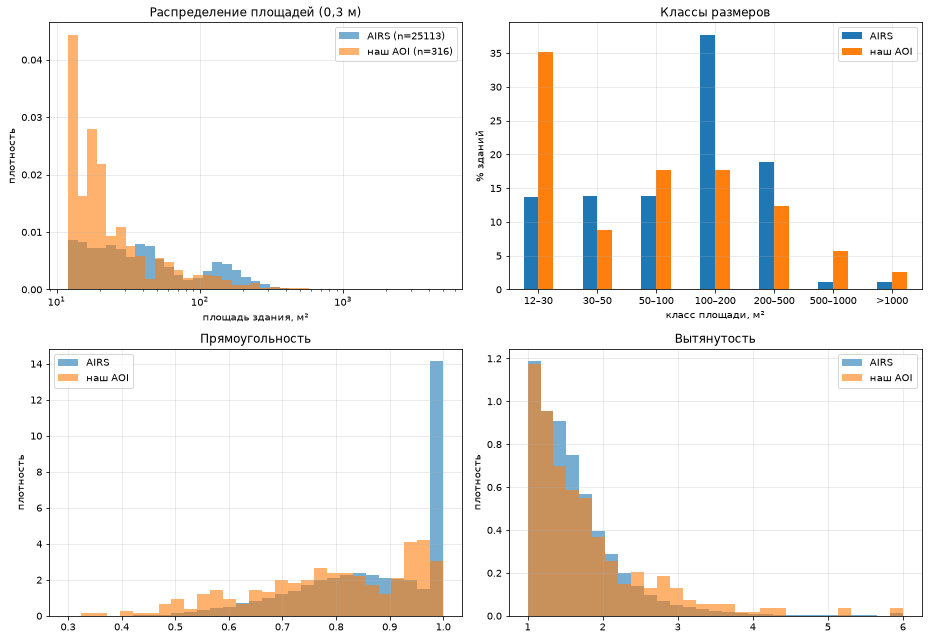

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
logbins = np.logspace(np.log10(12), np.log10(5000), 40)
ax[0, 0].hist(bld.area_m2, bins=logbins, density=True, alpha=0.6, label=f"AIRS (n={len(bld)})")
ax[0, 0].hist(ours_df.area_m2, bins=logbins, density=True, alpha=0.6,
              label=f"наш AOI (n={len(ours_df)})")
ax[0, 0].set(xscale="log", xlabel="площадь здания, м²", ylabel="плотность",
             title="Распределение площадей (0,3 м)")
ax[0, 0].legend()
(cls * 100).plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].set(xlabel="класс площади, м²", ylabel="% зданий", title="Классы размеров")
for col, a, title in (("rectangularity", ax[1, 0], "Прямоугольность"),
                      ("elongation", ax[1, 1], "Вытянутость")):
    rng_max = 1 if col == "rectangularity" else 6
    b = np.linspace(0.3 if col == "rectangularity" else 1, rng_max, 30)
    a.hist(bld[col].clip(upper=rng_max), bins=b, density=True, alpha=0.6, label="AIRS")
    a.hist(ours_df[col].clip(upper=rng_max), bins=b, density=True, alpha=0.6, label="наш AOI")
    a.set(title=title, ylabel="плотность")
    a.legend()
plt.tight_layout()
plt.savefig(FIG / "airs_buildings.png")
plt.show()

## 4. Цвет и домен

Пиксели снимка с уменьшением ×16 для AIRS (выборка тайлов) и тайлы нашего `train`/`val` (0,3 м).
Отдельно — пиксели **крыш** (по маскам/разметке): материал кровли важнее для модели, чем фон.
Зелень — индекс ExG = 2G − R − B > 20.

In [ ]:
def pixel_stats(img: np.ndarray, mask: np.ndarray | None) -> dict:
    valid = img.max(axis=0) > 0
    px = img[:, valid].T.astype(np.float32)
    roof = img[:, valid & mask].T.astype(np.float32) if mask is not None else None
    exg = 2 * px[:, 1] - px[:, 0] - px[:, 2]
    return {"px": px[:: max(1, len(px) // 20000)], "roof": None if roof is None else
            roof[:: max(1, len(roof) // 5000)], "green": float((exg > 20).mean())}


col_path = CACHE / "color.npz"
if col_path.exists():
    z = np.load(col_path)
    a_px, a_roof, a_green, o_px, o_roof, o_green = (z[k] for k in
                                                     ("a_px", "a_roof", "a_green", "o_px", "o_roof", "o_green"))
else:
    airs_st = []
    for r in sample.itertuples():
        with rasterio.open(r.image) as s:
            img = s.read(out_shape=(3, s.height // 16, s.width // 16), resampling=Resampling.average)
        with rasterio.open(r.label) as s:
            lab = s.read(1, out_shape=(s.height // 16, s.width // 16), resampling=Resampling.nearest) > 0
        airs_st.append(pixel_stats(img, lab))
    split_csv = pd.read_csv(REPO_ROOT / "data/labels/tiles_split.csv", dtype={"tile_id": str})
    our_st = []
    for s in ("train", "val"):
        lab_gdf = gpd.read_file(REPO_ROOT / f"data/labels/{s}/buildings.geojson")
        for t in split_csv.loc[split_csv.split == s, "tile_id"]:
            with rasterio.open(REPO_ROOT / f"data/tiles/{t}.tif") as src:
                img = src.read([1, 2, 3])
                g = lab_gdf.to_crs(src.crs)
                m = features.rasterize([(geom, 1) for geom in g.geometry], out_shape=img.shape[1:],
                                       transform=src.transform).astype(bool)
            our_st.append(pixel_stats(img, m))
    a_px, a_roof = np.vstack([x["px"] for x in airs_st]), np.vstack([x["roof"] for x in airs_st])
    o_px, o_roof = np.vstack([x["px"] for x in our_st]), np.vstack([x["roof"] for x in our_st])
    a_green, o_green = np.array([x["green"] for x in airs_st]), np.array([x["green"] for x in our_st])
    np.savez_compressed(col_path, a_px=a_px, a_roof=a_roof, a_green=a_green, o_px=o_px,
                        o_roof=o_roof, o_green=o_green)
color = pd.DataFrame({
    "AIRS, весь кадр": a_px.mean(0), "наш AOI, весь кадр": o_px.mean(0),
    "AIRS, крыши": a_roof.mean(0), "наш AOI, крыши": o_roof.mean(0)}, index=["R", "G", "B"]).T
color["яркость"] = color.mean(axis=1)
print(color.round(1))
print(f"доля зелени: AIRS {a_green.mean():.1%} | наш AOI {o_green.mean():.1%}")

                             R           G           B     яркость
AIRS, весь кадр     112.699997  115.000000  102.400002  110.000000
наш AOI, весь кадр  116.199997  128.699997  105.500000  116.800003
AIRS, крыши         148.899994  148.699997  153.399994  150.300003
наш AOI, крыши      171.100006  167.300003  173.399994  170.600006
доля зелени: AIRS 34.9% | наш AOI 60.2%


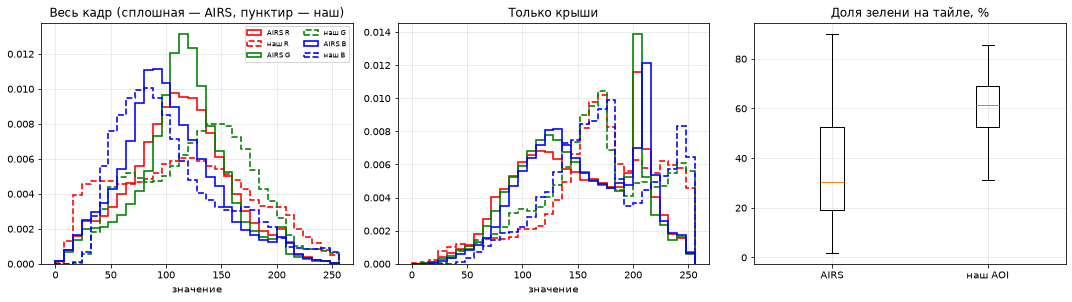

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
b = np.arange(0, 257, 8)
for i, (ch, c) in enumerate(zip("RGB", ("r", "g", "b"), strict=True)):
    ax[0].hist(a_px[:, i], bins=b, density=True, histtype="step", color=c, lw=1.6, label=f"AIRS {ch}")
    ax[0].hist(o_px[:, i], bins=b, density=True, histtype="step", color=c, ls="--", lw=1.6,
               label=f"наш {ch}")
    ax[1].hist(a_roof[:, i], bins=b, density=True, histtype="step", color=c, lw=1.6)
    ax[1].hist(o_roof[:, i], bins=b, density=True, histtype="step", color=c, ls="--", lw=1.6)
ax[0].set(title="Весь кадр (сплошная — AIRS, пунктир — наш)", xlabel="значение")
ax[0].legend(fontsize=7, ncol=2)
ax[1].set(title="Только крыши", xlabel="значение")
ax[2].boxplot([a_green * 100, o_green * 100], tick_labels=["AIRS", "наш AOI"])
ax[2].set(title="Доля зелени на тайле, %")
plt.tight_layout()
plt.savefig(FIG / "airs_color.png")
plt.show()

## 5. Примеры

Фрагменты 154×154 м (512 px на 0,3 м — как наш тайл) из AIRS с контурами маски на рабочем разрешении
и для сравнения тайлы нашего AOI с нашей разметкой.

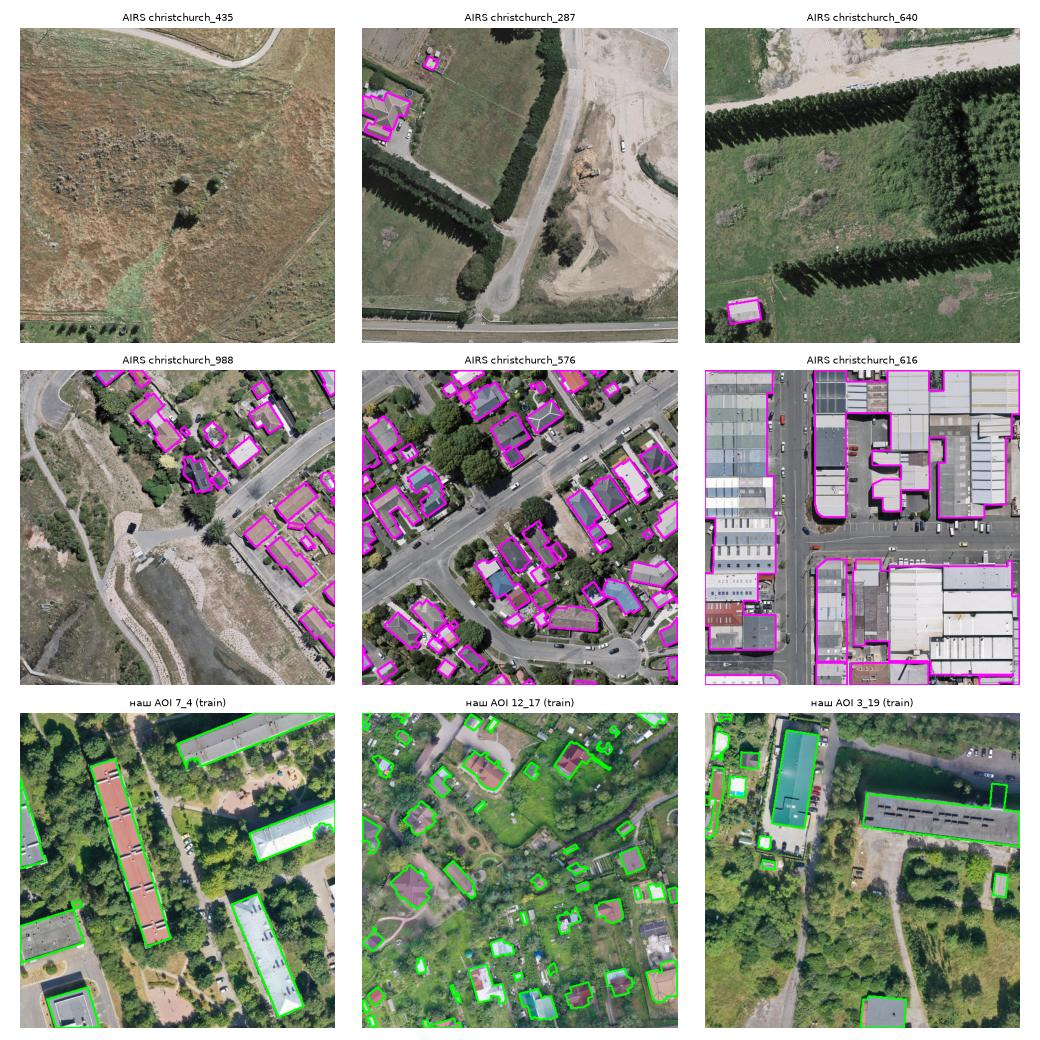

In [ ]:
def airs_chip(r) -> tuple[np.ndarray, np.ndarray]:
    with rasterio.open(r.image) as s:
        img = s.read(out_shape=(3, s.height // 4, s.width // 4), resampling=Resampling.average)
    with rasterio.open(r.label) as s:
        lab = s.read(1, out_shape=(s.height // 4, s.width // 4), resampling=Resampling.average,
                     out_dtype="float32") > 0.5
    y, x = rng.randrange(0, img.shape[1] - 512), rng.randrange(0, img.shape[2] - 512)
    return np.transpose(img[:, y:y + 512, x:x + 512], (1, 2, 0)).copy(), lab[y:y + 512, x:x + 512]


picks = cov[(cov.split == "train") & (cov.nodata_share < 0.05)].sort_values("roof_share")
picks = picks.iloc[np.linspace(len(picks) * 0.2, len(picks) - 1, 6).astype(int)]
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for a, r in zip(ax.flat[:6], meta.set_index("tile").loc[picks.tile].reset_index().itertuples(),
                strict=False):
    img, lab = airs_chip(r)
    cnts, _ = cv2.findContours(lab.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img, cnts, -1, (255, 0, 255), 2)
    a.imshow(img)
    a.set_title(f"AIRS {r.tile}", fontsize=9)
ours_lab = gpd.read_file(REPO_ROOT / "data/labels/train/buildings.geojson")
for a, t in zip(ax.flat[6:], ("7_4", "12_17", "3_19"), strict=True):
    with rasterio.open(REPO_ROOT / f"data/tiles/{t}.tif") as src:
        img = np.transpose(src.read([1, 2, 3]), (1, 2, 0)).copy()
        m = features.rasterize([(g, 1) for g in ours_lab.to_crs(src.crs).geometry],
                               out_shape=img.shape[:2], transform=src.transform).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img, cnts, -1, (0, 255, 0), 2)
    a.imshow(img)
    a.set_title(f"наш AOI {t} (train)", fontsize=9)
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIG / "airs_samples.jpg", dpi=80)
plt.close(fig)
display(Image(filename=str(FIG / "airs_samples.jpg")))  # JPEG keeps the notebook small

In [ ]:
report = {
    "dataset": "AIRS (Chen et al. 2019), Christchurch; imagery and outlines LINZ CC BY 4.0",
    "airs_dir": str(AIRS_DIR),
    "tiles": summary.to_dict(orient="index"),
    "tile_px": int(meta.w.iloc[0]), "gsd_m": GSD, "crs": meta.crs.iloc[0],
    "roof_share": cov.groupby("split").roof_share.describe().round(4).to_dict(orient="index"),
    "tiles_without_roofs": int((cov.roof_share == 0).sum()),
    "tiles_nodata_gt10pct": int((cov.nodata_share > 0.1).sum()),
    "sample_tiles": int(bld.tile.nunique()), "sample_buildings": len(bld),
    "density_per_km2": {"airs_all_median": float(dens.per_km2.median()),
                        "airs_builtup_median": float(built.per_km2.median()),
                        "ours": float(our_density)},
    "median_area_m2": {"airs": float(bld.area_m2.median()), "ours": float(ours_df.area_m2.median())},
    "size_classes_pct": (cls * 100).round(1).to_dict(),
    "rectangularity_median": {"airs": float(bld.rectangularity.median()),
                              "ours": float(ours_df.rectangularity.median())},
    "merge_rate_at_0_3m": float(merge_rate),
    "color_mean_rgb": color.round(1).to_dict(orient="index"),
    "green_share": {"airs": float(a_green.mean()), "ours": float(o_green.mean())},
}
REPORT.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: report[k] for k in ("density_per_km2", "median_area_m2", "merge_rate_at_0_3m",
                                         "green_share")}, indent=2, ensure_ascii=False))

{
  "density_per_km2": {
    "airs_all_median": 154.66666666666666,
    "airs_builtup_median": 884.4444444444445,
    "ours": 558.0760814525463
  },
  "median_area_m2": {
    "airs": 126.9,
    "ours": 58.49311788316366
  },
  "merge_rate_at_0_3m": 0.010137769690668041,
  "green_share": {
    "airs": 0.34910069108174696,
    "ours": 0.6017656097088288
  }
}


## 6. Выводы

Цифры — из прогона 2026-10-28 (`reports/external_airs_eda.json`); выборка зданий — 90 тайлов (60/15/15),
25 113 зданий; наш AOI — 316 зданий `train` + `val`.

| Показатель | AIRS | наш AOI | Что значит |
|---|---|---|---|
| Объём | 1046 тайлов 750×750 м, 580 км², 7,5 см | 24 тайла 154×154 м, 0,3 м | AIRS на порядки больше |
| Тайлы без крыш / с nodata > 10 % | 166 (16 %) / 110 (11 %) | — | пригородный пояс и края съёмки — отбрасывать |
| Медианная площадь здания | 127 м² | 58 м² | AIRS — дома, у нас много мелочи |
| Доля 12–30 м² (сараи, бани, гаражи) | 14 % | 35 % | мелкие постройки в AIRS почти не представлены |
| Доля > 500 м² | 2 % | 8 % | многоэтажек советского типа в AIRS нет |
| Плотность на застроенных тайлах | 884 на км² | 558 на км² | новозеландские пригороды плотнее |
| Прямоугольность (медиана) | 0,89 | 0,81 | крыши AIRS проще, наши — с пристройками |
| Потеря зданий при переходе 7,5 см → 0,3 м | 1,0 % | — | уменьшение ×4 безопасно |
| Доля зелени на тайле | 35 % | 60 % | наш снимок летний и «зелёный» |
| Средняя яркость крыш | 150 | 171 | наши крыши светлее, спектр шире |

1. **Данные целые и согласованные**: у каждого снимка есть маска, проекция одна (NZTM, EPSG:2193), разрешение
   7,5 см; краевые тайлы обрезаны. Наборы train/val/test перемешаны по всему городу, а не разбиты на районы.
2. **Покрытие двугорбое**: 44 % тайлов train — сельский пояс (< 1 % крыш), ядро города — 15–35 %. Для обучения
   нужны только застроенные и полностью снятые фрагменты; ночной прогон так и делает (≥ 90 % снимка, ≥ 1 здание).
3. **Перевод в наше разрешение 0,3 м** почти не склеивает соседние крыши (−1 % зданий) — подготовка ×4 корректна.
4. **Главное расхождение — размеры.** AIRS покрывает середину распределения (дома 100–500 м²), но почти не содержит
   двух наших «хвостов»: мелких дачных построек (35 % нашей разметки) и крупных многоэтажек. Ожидаемый эффект от
   подмешивания: лучше контуры частных домов, без выигрыша (или с потерей полноты) на сараях и панельках.
5. **Разметка — по крышам и аккуратная** в жилой застройке; в промзонах соседние склады слиты в одну маску
   (пример `christchurch_616`). Это та же склейка, от которой мы отучаем модель, — промзоны лучше брать с осторожностью.
6. **Домен по цвету заметно отличается**: наш снимок зеленее и ярче, у крыш AIRS узкий пик серого металла.
   Нужны цветовые аугментации (`hsv_s`, `hsv_v` — включены в ночном прогоне); следующий шаг при неудаче —
   выравнивание гистограмм AIRS под наш снимок.
7. **Как проверять ночной прогон**: кроме общего F1 на val сравнить полноту по классам площади — если AIRS «съест»
   мелкие постройки, F1 на дачах упадёт даже при росте на домах.